# Projeto 01: agente de recolha e entrega de alimentos locais

Fundamentos de Inteligência Artificial, Mestrado em Inteligência Artificial Aplicada, 2026-27. Grupo G09.

| Nome | Número |
|---|---|
| _(preencher)_ | _(preencher)_ |
| _(preencher)_ | _(preencher)_ |

## 1. Introdução

Uma plataforma liga pequenos produtores do distrito de Braga (e da Póvoa de Varzim) aos seus clientes.
Pelo meio está um centro de recolha com frota própria. Cada produto é recolhido no produtor dentro da
janela em que está disponível, descarregado no centro, carregado mais tarde e entregue ao cliente dentro
da janela de entrega.

Este trabalho constrói o agente que planeia as rotas. Para cada veículo, o agente escolhe as viagens que
servem todas as encomendas com o menor número de quilómetros. Tem de respeitar as janelas de recolha e
de entrega (que limitam a hora a que o serviço começa), a capacidade dos veículos, os 10 min de serviço
em cada paragem e a passagem pelo armazém: 15 min para descarregar, 15 min para carregar e no máximo
24 h lá dentro.

Resolvemos o problema com as três famílias de técnicas do enunciado: pesquisa informada (Greedy
best-first, A\* e A\* ponderado, com quatro heurísticas e duas formulações), pesquisa local (duas
variantes de Hill Climbing e Simulated Annealing) e CSP (backtracking com MRV, ordenação de valores,
forward checking e AC-3).

Este notebook tem o trabalho todo. Cada parte tem também um notebook próprio, com mais experiências: [`02_eda_tiny`](02_eda_tiny.ipynb) para a análise exploratória,
[`03_informed`](03_informed.ipynb) para a pesquisa informada, [`04_local_search`](04_local_search.ipynb)
para a pesquisa local e [`05_csp`](05_csp.ipynb) para o CSP.

O código está organizado assim:

```
data/tiny, data/small   CSV originais
src/model.py            entidades, simulador, custo, viabilidade, auditoria, verificador e figuras
src/informed.py         Greedy, A*, A* ponderado, A* por viagens, heurísticas h1–h4
src/local_search.py     Hill Climbing e Simulated Annealing
src/csp.py              formulação CSP, backtracking, FC, AC-3
run_experiments.py      corre as experiências e grava os resultados em reports/
tests/                  testes unitários
```

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import (load_problem, read_tables, audit, evaluate, check_solution, schedule_table, State,
                       plot_locations, plot_routes, plot_gantt, plot_histories)
from src.informed import greedy, astar, astar_trips, weighted_astar, catalog, HEURISTICS, h_mst, h_relaxed
from src.local_search import hill_climbing, simulated_annealing
from src.csp import solve, RoutingCSP

RUN_HEAVY = False  # True volta a correr as pesquisas longas (o A* exato demora minutos); False lê reports/

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
tiny = load_problem(ROOT / "data" / "tiny")
small = load_problem(ROOT / "data" / "small")
PROBLEMS = {"tiny": tiny, "small": small}


def load_solution(filename):
    """Lê uma solução gravada em reports/ como {veículo: [viagens]}."""
    return {int(vehicle): trips for vehicle, trips in json.loads((REPORTS / filename).read_text()).items()}


def print_routes(solution):
    for vehicle, trips in solution.items():
        print(f"Veículo {vehicle}:", " | ".join("W→" + "→".join(trip) + "→W" for trip in trips))

## 2. Análise exploratória dos dados

A análise completa está no notebook 02. Aqui ficam os números e as conclusões que contam para a
modelação.

In [2]:
tables = {name: read_tables(ROOT / "data" / name) for name in ("tiny", "small")}
pd.DataFrame({name: dict(
    encomendas=len(data["orders"]), linhas=len(data["order_items"]), produtores=len(data["producers"]),
    locais_entrega=len(data["delivery_locations"]), veiculos=len(data["vehicles"]),
    capacidade_kg=" + ".join(f"{c:.0f}" for c in data["vehicles"].capacity_kg),
    procura_kg=round(data["order_items"].weight_kg.sum(), 1)) for name, data in tables.items()})

,tiny,small
encomendas,12,25
linhas,40,80
produtores,3,6
locais_entrega,5,7
veiculos,2,2
capacidade_kg,150 + 200,250 + 300
procura_kg,270.0,580.0


In [3]:
audit_results = pd.concat([audit(data).assign(dataset=name) for name, data in tables.items()])
audit_results.pivot_table(index="status", columns="dataset", values="check", aggfunc="count", fill_value=0)

dataset,small,tiny
status,,
info,2,2
ok,67,67


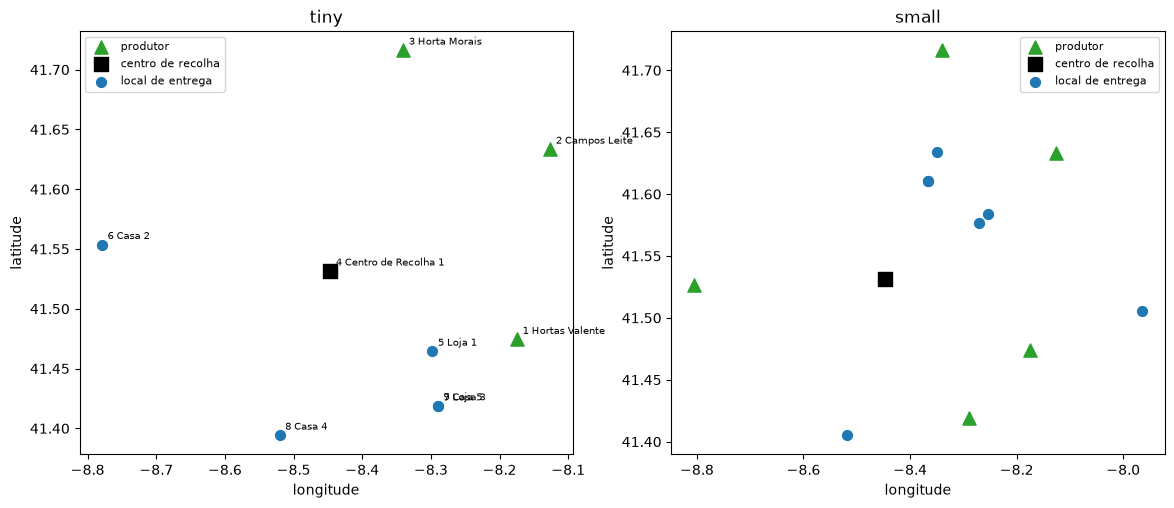

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_locations(tiny, axes[0])
axes[0].set_title("tiny")
plot_locations(small, axes[1], labels=False)
axes[1].set_title("small");

Os dados estão limpos: as 67 verificações da auditoria passam nos dois datasets. Ficam só duas notas
informativas: há locais de entrega com as mesmas coordenadas, e nenhuma linha foi encomendada depois de
abrir a janela de recolha.

As restrições que mais pesam são as temporais. No tiny, as recolhas acontecem de manhã
(06:45–12:15) e as entregas a meio do dia. Três encomendas são recolhidas no dia 30 e entregues no dia
31, com 25 a 29 h entre abrir a recolha e fechar a entrega, e é aqui que o limite de 24 h no armazém
começa a pesar.

O centro fica entre os produtores, a leste, e os clientes, a oeste e a sul, a 19–38 km de cada local.
Como cada viagem é uma ida e volta ao centro, o número de viagens domina o custo. No small, a procura
(580 kg) passa a capacidade da frota (550 kg), por isso cada veículo tem de fazer mais do que uma
viagem.

## 3. Modelação

### 3.1 Decisões

| Decisão | Porquê |
|---|---|
| O tempo conta-se em minutos desde `start_date 00:00` | Simplifica as contas; as datas só aparecem nos resultados. |
| Um pedido de recolha junta as linhas do mesmo produtor cujas janelas se intersetam (*interval stabbing*), até à capacidade do veículo mais pequeno | Numa paragem recolhe-se tudo o que está disponível ao mesmo tempo. No tiny, 40 linhas dão 6 recolhas. |
| Um pedido de entrega é uma encomenda | As linhas de uma encomenda têm o mesmo destino e a mesma janela. |
| A janela de recolha começa em `max(availability_start, order_datetime)` | Não se recolhe nada antes de o cliente encomendar. |
| Uma rota é uma lista de viagens, e cada viagem sai do centro e volta lá | É o que o fluxo produtor → armazém → cliente impõe. |
| Cada viagem só tem recolhas ou só tem entregas | Simplifica a precedência: o que uma viagem recolhe fica disponível no armazém quando ela acaba. |
| Nenhuma viagem atravessa a meia-noite | Evita um veículo parado a noite inteira num cliente à espera da janela do dia seguinte. |
| Os veículos saem *just in time* | Chegam à primeira paragem quando a janela abre, o que reduz esperas e tempo no armazém. |
| Um veículo pode entregar o que outro recolheu | Basta que o produto já esteja descarregado no armazém. |
| O objetivo é minimizar os km totais | O tempo de rota e o *makespan* aparecem como métricas secundárias. |
| A refrigeração é ignorada | Os dados não dizem que produtos precisam de frio. |

### 3.2 Classes principais

Em `src/model.py`, um `Item` é uma linha de encomenda, com peso, janela de disponibilidade e janela de
entrega. Um `Request` é aquilo que o agente agenda: uma recolha (grupo de linhas de um produtor) ou uma
entrega (uma encomenda), com local, janela, peso e, nas entregas, as recolhas de que depende (`deps`).
`Vehicle` guarda capacidade, refrigeração e velocidade, e `Problem` junta tudo: pedidos, frota, centro,
matriz de distâncias e tempos, e regras. `State` e `VState` são os nós da pesquisa informada. Uma
solução é um dicionário `{veículo: [viagem, viagem, ...]}`, em que cada viagem é uma lista de pedidos.

### 3.3 Custo e viabilidade

`evaluate(problem, solution)` simula as viagens todas e devolve os km e as violações: minutos de atraso,
kg a mais, minutos a mais no armazém, pedidos em falta ou repetidos, bloqueios e viagens que passam a
meia-noite.

Os veículos influenciam-se uns aos outros através do armazém, porque uma viagem de entrega só pode
carregar depois de descarregadas as recolhas de que depende. Por isso a simulação avança sempre o
veículo cuja próxima viagem já tem tudo pronto. Se nenhum puder avançar, há uma dependência circular e a
solução fica bloqueada.

A pesquisa local precisa de comparar também soluções inviáveis, e para isso usa um custo penalizado:


`km + 100·(atraso + excesso de carga + excesso de permanência) + 10 000·(erros estruturais)`

In [5]:
# os 18 pedidos do tiny depois do agrupamento
rows = [dict(id=request_id, tipo=request.kind, local=request.loc,
             janela=f"{tiny.clock(request.tw[0])} – {tiny.clock(request.tw[1])}",
             kg=request.weight, linhas=len(request.items), depende_de=", ".join(request.deps))
        for request_id, request in tiny.requests.items()]
pd.DataFrame(rows).set_index("id").T

id,P1,P2,P3,P4,P5,P6,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12
tipo,P,P,P,P,P,P,D,D,D,D,D,D,D,D,D,D,D,D
local,1,1,2,2,3,3,7,8,6,7,5,7,9,6,9,8,5,6
janela,30 09:30 – 30 09:45,31 09:00 – 31 11:15,30 09:00 – 30 10:30,31 08:15 – 31 10:00,30 08:00 – 30 09:45,31 07:45 – 31 09:45,31 10:30 – 31 12:45,31 07:15 – 31 10:15,31 11:30 – 31 14:15,30 11:30 – 30 13:45,31 10:30 – 31 12:30,31 10:45 – 31 13:15,31 10:45 – 31 13:30,31 09:30 – 31 12:00,31 08:15 – 31 09:45,30 11:45 – 30 14:00,30 10:15 – 30 14:00,30 12:15 – 30 14:45
kg,52.0,41.1,77.6,29.9,37.3,32.1,22.0,6.8,21.6,26.3,9.3,16.7,33.5,18.8,36.7,9.2,18.0,51.1
linhas,8,5,9,5,7,6,4,2,4,3,2,2,4,3,5,2,4,5
depende_de,,,,,,,"P2, P4, P6","P1, P5","P2, P4, P6","P1, P3, P5","P4, P6","P4, P6","P2, P4","P3, P5","P1, P3, P5","P1, P3","P1, P3, P5","P1, P3"


In [6]:
# uma solução feita à mão e uma variante inválida, com a entrega D3 antes das recolhas
manual = {1: [["P4", "P6", "P2"], ["D3"]],
          2: [["P5", "P1", "P3"], ["D4", "D11", "D10", "D12"], ["D2", "D9", "D8"], ["D1", "D6", "D5", "D7"]]}
broken = {1: [["D3"], ["P4", "P6", "P2"]], 2: manual[2]}
pd.DataFrame({"manual": evaluate(tiny, manual).summary(), "inválida": evaluate(tiny, broken).summary()})

,manual,inválida
km,663.81,397.58
feasible,True,False
trips,6,3
late_min,0.0,0.0
over_kg,0.0,0.0
dwell_excess_min,0.0,0.0
unserved,0,0
deadlock,0,8
overnight,0,0
makespan_min,2243.5,2078.5


### 3.4 Verificador linha a linha

Para não depender só do simulador que os algoritmos usam, `check_solution` reconstrói cada solução como
uma lista explícita de paragens (`pickup`, `unload`, `load`, `delivery`, `return`), linha a linha, e
confere-a contra os CSV originais, sem passar pelos pedidos agregados. Verifica os tempos de viagem e as
janelas de cada linha (incluindo `order_datetime`), a carga ao longo da rota, que cada linha é
recolhida, descarregada, carregada e entregue exatamente uma vez, que nada é carregado antes de ser
descarregado, a permanência máxima, o regresso ao centro, o horizonte e a capacidade do armazém. O
verificador vem de um protótipo anterior do grupo, adaptado a este código.

In [7]:
manual_eval = evaluate(tiny, manual)
check = check_solution(tiny, manual_eval)
print("simulador:", round(manual_eval.km, 2), "km, viável =", manual_eval.feasible,
      "| verificador:", check.valid, round(check.km, 2), "km")
print("solução inválida:", check_solution(tiny, evaluate(tiny, broken)).errors[:3])

simulador: 663.81 km, viável = True | verificador: True 663.81 km
solução inválida: ['linha 1: pickup feito 0 vezes (esperado 1)', 'linha 1: unload feito 0 vezes (esperado 1)', 'linha 1: load feito 0 vezes (esperado 1)']


## 4. Pesquisa informada

### 4.1 Formulação

Um estado é uma solução parcial. Para cada veículo guarda onde está, a hora, a viagem em curso (tipo e
pedidos) e as viagens já fechadas; guarda também os pedidos já servidos e a hora a que cada recolha
chegou ao armazém. No estado inicial, os dois veículos estão no centro às 00:00 do dia 30 e nada foi
servido. O objetivo é ter tudo servido e os veículos de volta ao centro. O custo g de um caminho são os
km já percorridos.

Cada ação mexe num só veículo: ou visita um pedido por servir compatível com a viagem em curso (ou abre
uma viagem nova), ou fecha a viagem e volta ao centro. Uma entrega só pode ser visitada quando todas as
suas recolhas já estão no armazém. Os sucessores que falham uma janela, a capacidade, a permanência ou
a regra da meia-noite são descartados.

Há duas podas, ambas exatas: nunca cortam uma solução viável. A primeira deteta becos sem saída, ou
seja, um pedido que, mesmo no cenário mais otimista, já não consegue começar dentro da janela. Nas
entregas, esse cenário conta com a hora mais cedo a que as recolhas podem estar no armazém, e o limite
de 24 h é testado com a hora de carga mais cedo possível da viagem, que pode vir de outra entrega com
janela anterior. Uma primeira versão usava a hora de carga *just in time* da própria entrega e, num caso
de teste, cortava a única solução viável; ficou um teste unitário para isso. A segunda poda é por
dominância: entre dois estados com os mesmos pedidos servidos e as mesmas viagens em curso, descarta-se
o que tem mais custo e relógios mais tardios. As horas de chegada ao armazém só são comparadas quando o
limite de 24 h não pode ser violado; nos outros casos têm de ser iguais.

### 4.2 Segunda formulação: uma ação, uma viagem

Na formulação anterior, a mesma solução pode ser construída por muitas sequências de ações diferentes.
Na segunda, todos os veículos estão no centro entre ações, e cada ação é "o veículo v faz a viagem T".

Antes da pesquisa constrói-se um catálogo com todas as viagens que podem entrar numa solução (conjunto
de pedidos e ordem de visita), usando a partida mais cedo de cada grupo, já que partir mais tarde nunca
torna viável uma viagem inviável. Para uma ordem fixa, o horário tem forma fechada: o regresso ao centro
é `max(D + δ, c)`, em que D é a hora de partida, δ a duração sem esperas e c o regresso mais cedo que as
janelas permitem, e a viagem é viável se `D ≤ Dmax`. Entre duas ordens do mesmo conjunto, descarta-se a
que é pior ou igual em km, δ, c, Dmax e hora de carga, porque perde para qualquer partida e qualquer
continuação.

Na pesquisa, cada viagem é testada no contexto real (veículo livre, hora a que as recolhas chegaram de
facto ao armazém, capacidade do veículo, 24 h, meia-noite) com as regras do simulador, e um teste
unitário confirma que os dois horários coincidem. O estado, o custo, as podas e as heurísticas são os
da primeira formulação. Cada passo é maior: um nó expandido corresponde a uma viagem acrescentada.

### 4.3 Heurísticas

As quatro heurísticas são admissíveis: dão um limite inferior dos km que faltam.

h1 (desvio máximo) é o máximo, sobre os pedidos por servir, da distância do veículo mais próximo até ao
pedido mais a distância do pedido ao centro. Pela desigualdade triangular, nenhum completamento é mais
curto. É simples e fraca.

h2 (arcos mínimos) agrupa os pedidos por nó (local, dia, tipo), sabendo que só nós do mesmo dia e tipo
podem partilhar viagem. Cada nó por servir precisa de um arco de entrada (do centro, de outro nó do
grupo ou de um veículo com uma viagem desse grupo em curso) e cada viagem que ainda falta precisa de um
arco de regresso. A heurística soma os mínimos.

h3 (MST por grupo) parte de uma observação: se tirarmos o arco de regresso a cada viagem que falta, o
que sobra liga o centro a todos os nós por servir e custa pelo menos uma árvore de cobertura mínima.
Junta-lhe um limite do tipo *1-tree* e o número mínimo de viagens de cada grupo, calculado a partir do
peso e dos pares de pedidos que não podem ir juntos (janelas que não encadeiam, ou entregas cujos
produtos ficam prontos tarde demais para a outra).

h4 (relaxação exata por grupo) resolve de forma exata, em cada grupo (dia, tipo), um problema mais
simples: veículos ilimitados com a capacidade do maior, e entregas que saem assim que os produtos podem
estar no armazém. Mantém as janelas, os tempos de serviço e de carga e descarga, a capacidade e a regra
da meia-noite. Enumera as viagens possíveis do grupo e escolhe, por programação dinâmica sobre
subconjuntos, a combinação mais barata que cobre os pedidos por servir. Como o problema real tem mais
restrições, não pode custar menos. Por cada viagem em curso subtrai d(centro, veículo), e em cada grupo
fica com o máximo entre este valor e a h3.

O Greedy usa f = h e expande sempre o veículo com o relógio mais atrasado, para não deixar um veículo
saltar para o dia seguinte enquanto o outro ainda tem trabalho. O A\* usa f = g + h sem essa regra, e
por isso é ótimo neste espaço. Testámos também o A\* ponderado, com f = g + w·h.

In [8]:
# valor de cada heurística no estado inicial
pd.DataFrame({name: {heuristic_name: round(heuristic(problem, State.initial(problem)), 2)
                     for heuristic_name, heuristic in HEURISTICS.items()}
              for name, problem in PROBLEMS.items()})

,tiny,small
h1_max_detour,75.32,104.66
h2_min_arcs,395.95,419.05
h3_mst,441.83,469.13
h4_relaxed,533.09,757.84
h0_zero,0.00,0.00


### 4.4 Greedy no tiny

In [9]:
greedy_results = {}
for name, heuristic in HEURISTICS.items():
    if name == "h0_zero":
        continue
    greedy_results[name] = greedy(tiny, heuristic)
    print(name, greedy_results[name].summary())

h1_max_detour {'algorithm': 'Greedy', 'heuristic': 'h_max_detour', 'cost_km': 707.16, 'expanded': 46, 'generated': 156, 'pruned': 68, 'seconds': 0.006, 'found': True, 'complete': True}
h2_min_arcs {'algorithm': 'Greedy', 'heuristic': 'h_min_arcs', 'cost_km': 674.14, 'expanded': 29, 'generated': 91, 'pruned': 30, 'seconds': 0.004, 'found': True, 'complete': True}
h3_mst {'algorithm': 'Greedy', 'heuristic': 'h_mst', 'cost_km': 625.46, 'expanded': 29, 'generated': 92, 'pruned': 36, 'seconds': 0.006, 'found': True, 'complete': True}
h4_relaxed {'algorithm': 'Greedy', 'heuristic': 'h_relaxed', 'cost_km': 611.13, 'expanded': 28, 'generated': 87, 'pruned': 30, 'seconds': 0.006, 'found': True, 'complete': True}


### 4.5 A\* nos dois datasets

O A\* paragem a paragem demora minutos por heurística no tiny, por isso os resultados vêm de
`reports/informed.csv`, gerado por `run_experiments.py`. Com `RUN_HEAVY = True` voltam a ser calculados
aqui. O A\* por viagens é rápido e corre na secção 4.6.

In [10]:
if RUN_HEAVY:
    for name in ("h1_max_detour", "h2_min_arcs", "h3_mst"):
        print(name, astar(tiny, HEURISTICS[name], max_expansions=1_000_000).summary())
    print(astar_trips(small, h_relaxed).summary())
informed = pd.read_csv(REPORTS / "informed.csv")
informed[["dataset", "algorithm", "heuristic_name", "cost_km", "expanded", "generated", "pruned", "seconds",
          "complete", "item_check"]]

,dataset,algorithm,heuristic_name,cost_km,expanded,generated,pruned,seconds,complete,item_check
0,tiny,Greedy,h1_max_detour,707.16,46,156,68,0.005,True,True
1,tiny,Greedy,h2_min_arcs,674.14,29,91,30,0.004,True,True
2,tiny,Greedy,h3_mst,625.46,29,92,36,0.004,True,True
3,tiny,Greedy,h4_relaxed,611.13,28,87,30,0.006,True,True
4,tiny,A*,h1_max_detour,NaN,1000000,5868823,3881922,197.977,False,NaN
5,tiny,A*,h2_min_arcs,NaN,1000000,5662950,3388804,218.486,False,NaN
6,tiny,A*,h3_mst,533.09,709786,4090385,2359117,167.704,True,True
7,tiny,A*,h4_relaxed,533.09,7302,33048,16194,0.991,True,True
8,tiny,WA*(w=1.2),h3_mst,533.09,100582,568563,319654,18.565,True,True
9,tiny,WA*(w=1.5),h3_mst,533.09,196,1025,381,0.036,True,True


In [11]:
# o A* ponderado é rápido e corre aqui
for weight in (1.5, 2.0):
    print(weight, weighted_astar(tiny, h_mst, weight).summary())

1.5 {'algorithm': 'WA*(w=1.5)', 'heuristic': 'h_mst', 'cost_km': 533.09, 'expanded': 196, 'generated': 1025, 'pruned': 381, 'seconds': 0.037, 'found': True, 'complete': True}
2.0 {'algorithm': 'WA*(w=2.0)', 'heuristic': 'h_mst', 'cost_km': 553.08, 'expanded': 56, 'generated': 302, 'pruned': 62, 'seconds': 0.016, 'found': True, 'complete': True}


### 4.6 A\* por viagens

In [12]:
for name, problem in PROBLEMS.items():
    start = time.perf_counter()
    trip_catalog = catalog(problem)
    catalog_seconds = time.perf_counter() - start
    result = astar_trips(problem, h_relaxed)
    print(f"{name}: catálogo com {trip_catalog.raw_orders} ordens -> {len(trip_catalog.options)} opções "
          f"({catalog_seconds:.1f} s) | {result.summary()}")

tiny: catálogo com 242 ordens -> 111 opções (0.0 s) | {'algorithm': 'A*-viagens', 'heuristic': 'h_relaxed', 'cost_km': 533.09, 'expanded': 7, 'generated': 281, 'pruned': 163, 'seconds': 0.013, 'found': True, 'complete': True}


small: catálogo com 272062 ordens -> 4067 opções (20.3 s) | {'algorithm': 'A*-viagens', 'heuristic': 'h_relaxed', 'cost_km': 757.84, 'expanded': 19, 'generated': 39369, 'pruned': 25620, 'seconds': 3.841, 'found': True, 'complete': True}


### 4.7 Rotas ótimas do tiny

{'km': 533.09, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2188.3, 'route_min': 922.5}
verificador: True
Veículo 1: W→P6→P4→P2→W | W→D1→D6→D7→D5→W
Veículo 2: W→P5→P3→P1→W | W→D11→D4→D10→D12→W | W→D2→D9→W | W→D8→D3→W


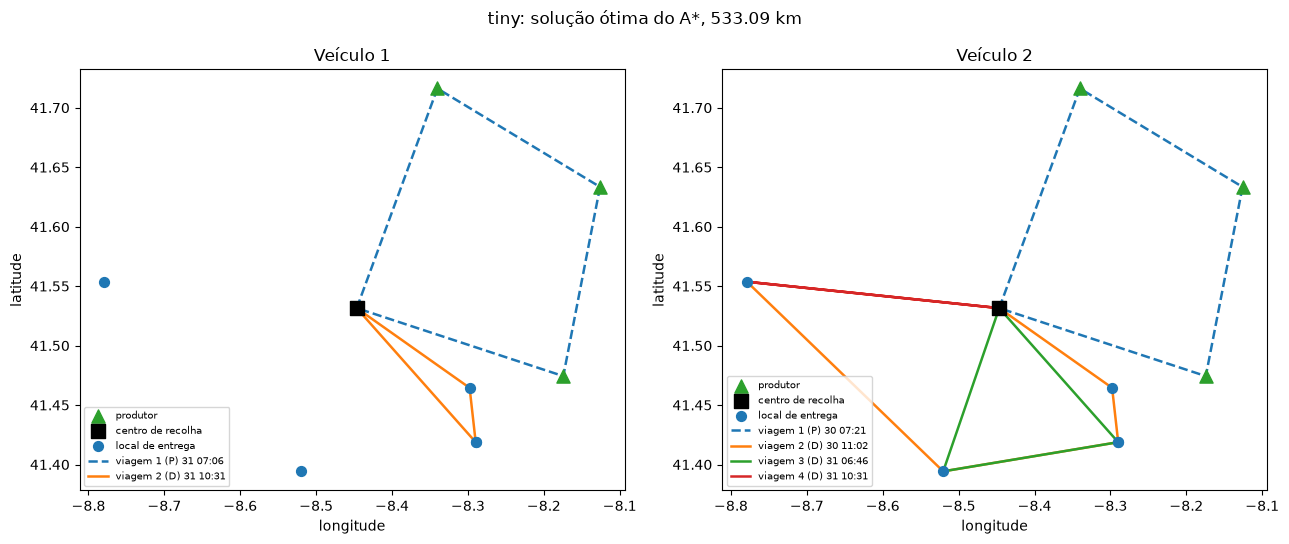

In [13]:
best_tiny = load_solution("solution_tiny_astar.json")
tiny_eval = evaluate(tiny, best_tiny)
print(tiny_eval.summary())
print("verificador:", check_solution(tiny, tiny_eval).valid)
print_routes(best_tiny)
plot_routes(tiny, best_tiny, f"tiny: solução ótima do A*, {tiny_eval.km:.2f} km");

,vehicle,trip,stop,kind,arrival,start,window,weight
0,1,0,W,P,NaN,31 07:06,,NaN
1,1,0,P6,P,31 07:45,31 07:45,31 07:45-31 09:45,32.1
2,1,0,P4,P,31 08:29,31 08:29,31 08:15-31 10:00,29.9
3,1,0,P2,P,31 09:11,31 09:11,31 09:00-31 11:15,41.1
4,1,0,W,P,31 10:01,NaN,,NaN
5,1,1,W(carga),D,NaN,31 10:31,,NaN
6,1,1,D1,D,31 11:03,31 11:03,31 10:30-31 12:45,22.0
7,1,1,D6,D,31 11:13,31 11:13,31 10:45-31 13:15,16.7
8,1,1,D7,D,31 11:23,31 11:23,31 10:45-31 13:30,33.5
9,1,1,D5,D,31 11:42,31 11:42,31 10:30-31 12:30,9.3


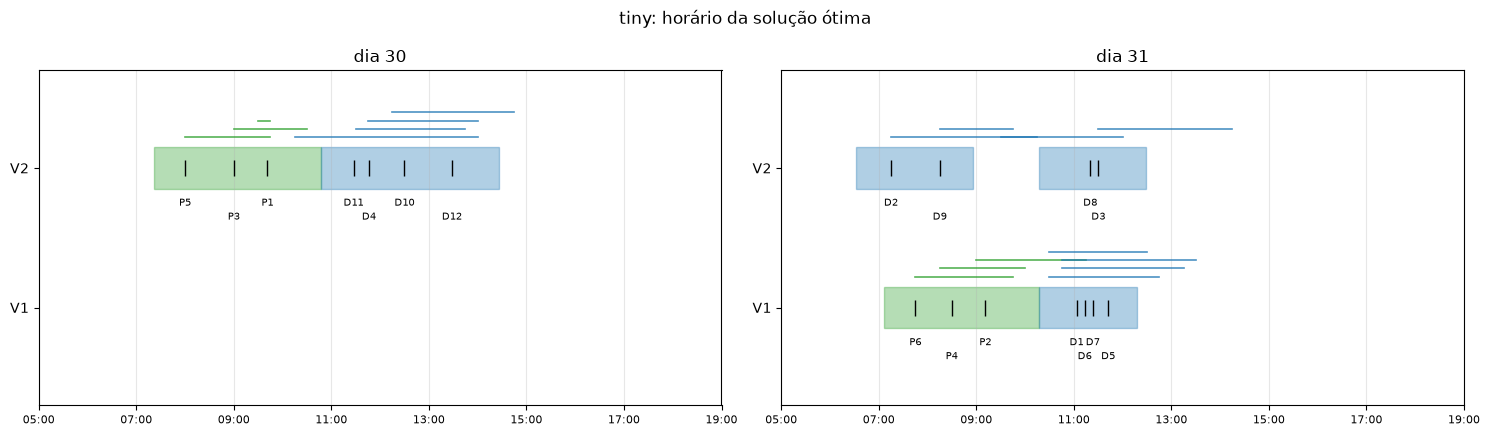

In [14]:
plot_gantt(tiny, tiny_eval, "tiny: horário da solução ótima");
schedule_table(tiny, tiny_eval)

### Análise

A qualidade da heurística decide quase tudo. No estado inicial do tiny, h1 vale 75,32 km (14% do
ótimo), h3 vale 441,83 km (83%) e h4 vale 533,09 km, o próprio ótimo. Isso vê-se no A\* paragem a
paragem: com h1 e h2 não há solução ao fim de 1 000 000 expansões (198 s e 218 s); com h3 chega a
533,09 km em 709 786 expansões (168 s); com h4 chega lá em 7 302 expansões (0,99 s).

Passar a ações ao nível da viagem encolhe o espaço de pesquisa de forma drástica. Com h4, o A\* resolve
o tiny em 7 expansões (0,01 s) e o small, com 757,84 km, em 19 expansões (2,92 s). Paragem a paragem,
mesmo com h4, o small fica sem solução ao fim de 150 000 expansões (81,49 s). O catálogo do small tem
272 062 ordens possíveis, que a dominância reduz a 4 067 opções; construí-lo demora 18–36 s, conforme a
máquina, e só se faz uma vez.

Estes valores provam os ótimos. A h4 é um limite inferior e, no estado inicial, vale 533,09 km no tiny e
757,84 km no small, exatamente o custo das soluções encontradas, que o verificador confirma como
viáveis. Um limite inferior igual ao custo de uma solução viável prova que 533,09 km é o ótimo do tiny e
757,84 km o do small, dentro do modelo (pedidos agrupados, viagens homogéneas, nenhuma viagem a passar
a meia-noite). A prova não depende das podas do A\*. No tiny há ainda uma confirmação independente: o
A\* paragem a paragem com h3 chega ao mesmo valor.

O Greedy é rápido mas fica longe: 625,46 km com h3 (17,3% acima do ótimo) e 611,13 km com h4 (14,6%
acima). O A\* ponderado com h3 e w = 1,5 encontra os 533,09 km com apenas 196 expansões, embora sem
garantia (o limite teórico é 1,5 vezes o ótimo).

A solução ótima do tiny tem 6 viagens:

| Veículo | Viagem | Saída | Pedidos |
|---|---|---|---|
| 1 | recolha | 07:06 do dia 31 | P6, P4, P2 |
| 1 | entrega | 10:31 do dia 31 | D1, D6, D7, D5 |
| 2 | recolha | 07:21 do dia 30 | P5, P3, P1 |
| 2 | entrega | 11:02 do dia 30 | D11, D4, D10, D12 |
| 2 | entrega | 06:46 do dia 31 | D2, D9 |
| 2 | entrega | 10:31 do dia 31 | D8, D3 |

As encomendas D2 e D9 foram recolhidas na véspera e têm de chegar até às 10:15 e às 09:45 do dia 31. A
essa hora as recolhas do dia ainda não voltaram ao armazém, por isso seguem sozinhas numa viagem de
manhã cedo.

## 5. Pesquisa local

A pesquisa local trabalha sobre soluções completas `{veículo: [viagens]}` e compara-as pelo custo
penalizado da secção 3.3.

A vizinhança tem três movimentos, e nenhum mistura recolhas e entregas na mesma viagem: *relocate* tira
um pedido e põe-no noutra posição, noutra viagem, noutro veículo ou numa viagem nova; *swap* troca dois
pedidos do mesmo tipo; *2-opt* inverte um segmento dentro de uma viagem.

O Hill Climbing *steepest* avalia a vizinhança toda, fica com o melhor vizinho viável e pára num ótimo
local. A variante *first improvement* percorre a vizinhança por ordem aleatória e aceita o primeiro
vizinho viável que melhora. O Simulated Annealing escolhe um vizinho ao acaso e aceita-o com
probabilidade exp(−Δ/T), com arrefecimento geométrico (T₀ = 30, α = 0,9998, 30 000 iterações). Pode
passar por soluções inviáveis, mas devolve a melhor solução viável que encontrou. Os três partem da
solução do Greedy com h3.

In [15]:
start = greedy_results["h3_mst"].solution
hc_steepest = hill_climbing(tiny, start, "steepest")
hc_first = hill_climbing(tiny, start, "first", seed=0)
annealing = simulated_annealing(tiny, start, t0=30, alpha=0.9998, iters=30_000, seed=0)
pd.DataFrame([hc_steepest.summary(), hc_first.summary(), annealing.summary()])

,algorithm,initial_km,final_km,improvement_pct,feasible,iterations,evaluated,seconds
0,HC-steepest,625.46,533.09,14.77,True,5,2714,0.130
1,HC-first,625.46,533.09,14.77,True,5,705,0.049
2,SA,625.46,533.09,14.77,True,30000,30000,1.394


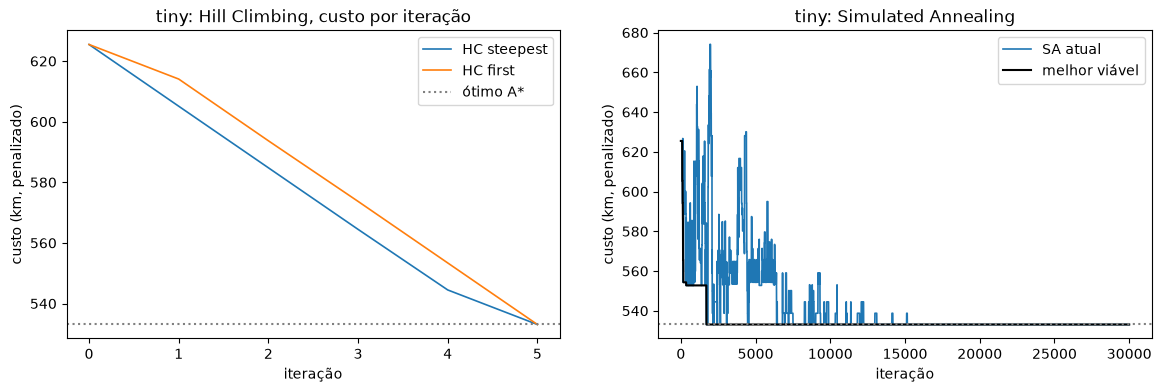

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_histories({"HC steepest": dict(current=hc_steepest.history), "HC first": dict(current=hc_first.history)},
               "tiny: Hill Climbing, custo por iteração", ax=axes[0])
axes[0].axhline(tiny_eval.km, color="grey", ls=":", label="ótimo A*")
axes[0].legend()
plot_histories({"SA atual": dict(current=annealing.history)}, "tiny: Simulated Annealing", ax=axes[1], cap=800)
best_so_far = pd.Series(annealing.best_history).replace(float("inf"), None)
axes[1].plot(best_so_far.index, best_so_far.values, color="black", lw=1.5, label="melhor viável")
axes[1].axhline(tiny_eval.km, color="grey", ls=":")
axes[1].legend();

In [17]:
print("movimentos aceites pelo HC steepest:")
for move in hc_steepest.moves:
    print("  ", move)

movimentos aceites pelo HC steepest:
   ('relocate', 'P6', 1, 0, 0)
   ('relocate', 'P2', 1, 0, 2)
   ('relocate', 'P1', 2, 0, 2)
   ('swap', 'D10', 'D11')
   ('relocate', 'D5', 1, 1, 0)


In [18]:
local = pd.read_csv(REPORTS / "local.csv")
local.groupby(["dataset", "algorithm"]).agg(
    km_min=("final_km", "min"), km_media=("final_km", "mean"), km_max=("final_km", "max"),
    segundos=("seconds", "mean"), avaliacoes=("evaluated", "mean"), corridas=("seed", "count")).round(2)

km_min  km_media  km_max  segundos  avaliacoes  corridas
dataset algorithm                                                            
small   HC-first     799.35    817.06  834.22      0.48      4030.2         5
        HC-steepest  799.35    799.35  799.35      0.97     15904.0         1
        SA           771.69    801.54  821.94      2.18     30000.0         5
tiny    HC-first     533.09    533.09  533.09      0.05       821.8         5
        HC-steepest  533.09    533.09  533.09      0.10      2714.0         1
        SA           533.09    533.09  533.09      1.23     30000.0         5

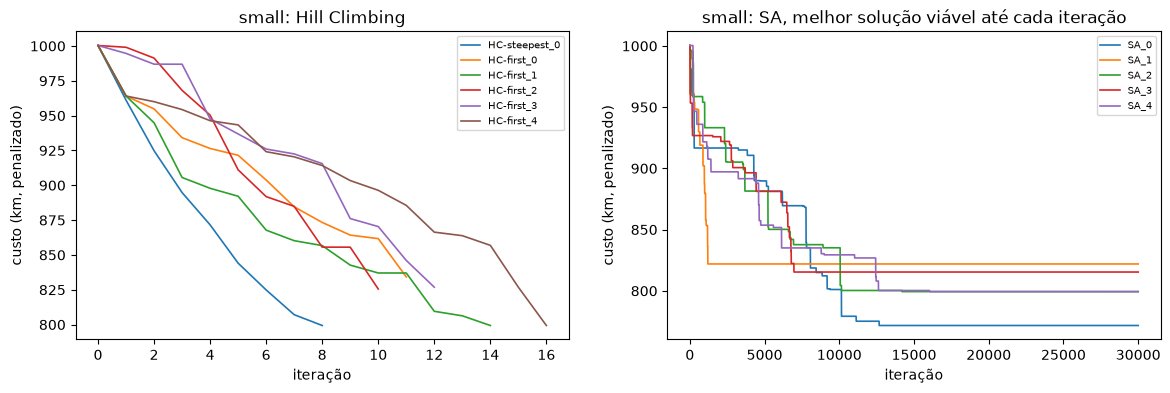

In [19]:
histories = json.loads((REPORTS / "local_histories.json").read_text())["small"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_histories({run: history for run, history in histories.items() if run.startswith("HC")},
               "small: Hill Climbing", ax=axes[0])
plot_histories({run: dict(current=[km if km != float("inf") else None for km in history["best"]])
                for run, history in histories.items() if run.startswith("SA")},
               "small: SA, melhor solução viável até cada iteração", ax=axes[1]);

### Análise

No tiny, os três métodos partem dos 625,46 km do Greedy e chegam todos ao ótimo de 533,09 km. O HC
*steepest* precisa de 5 iterações (cerca de 0,1 s), com quatro *relocate* e um *swap*. Para comparar, o A\*
paragem a paragem com h3 precisou de quase 3 minutos para provar que esse valor é ótimo (com h4, ou por
viagens, menos de 1 s).

No small, o HC *steepest* desce de 1000,35 para 799,35 km, 5,5% acima do ótimo provado (757,84 km). O
*first improvement* termina entre 799,35 e 834,22 km nas 5 sementes, porque a ordem aleatória leva a
ótimos locais diferentes. O SA fica entre 771,69 e 821,94 km. A melhor corrida, a 1,8% do ótimo, bate o
HC porque o SA aceita pioras temporárias e sai de ótimos locais onde o HC fica preso. Em média
(801,54 km), porém, não bate o HC *steepest*: só 1 das 5 sementes fica abaixo dele.

Quanto ao custo, o HC *steepest* avalia a vizinhança inteira em cada iteração: cerca de 470 vizinhos no
tiny e 1 770 no small, contando a última passagem, que confirma o ótimo local. O *first improvement*
gasta menos por iteração e, no small, faz mais iterações (10–16 contra 8). O SA tem custo fixo: 30 000
avaliações.

## 6. CSP

### 6.1 Formulação

Há uma variável X_r por pedido, recolha ou entrega: 18 no tiny e 37 no small. O domínio de cada
variável são triplos (veículo, dia, posição). Cada dia segue um modelo fixo de posições de viagem,
`D-P-D-D-P-D-D`, em que D é uma viagem de entrega e P uma de recolha. Os pedidos com o mesmo valor formam
uma viagem.

A ordem de cada viagem é escolhida ao simular o horário, a partir da hora a que o veículo fica livre e
a que as recolhas chegam ao armazém: fica a ordem mais curta que cumpre as janelas e o limite de 24 h.
Numa viagem com até 6 pedidos experimentamos todas as ordens (6! = 720). As maiores viagens do small
têm 11 pedidos, o que daria cerca de 40 milhões de ordens a testar em cada verificação do horário. Por
isso, acima de 6 pedidos experimentamos só algumas ordens razoáveis (por fecho de janela, por abertura
de janela e pelo vizinho mais próximo, cada uma também encurtada com 2-opt). É rápido, mas pode falhar
a melhor ordem.

As restrições unárias obrigam o tipo da posição a coincidir com o tipo do pedido, e o dia da posição com
o dia da janela (nenhuma viagem passa a meia-noite). As binárias, que o forward checking e o AC-3 usam,
são quatro:

* dois pedidos na mesma viagem não passam a capacidade do veículo (w_a + w_b ≤ capacidade);
* dois pedidos na mesma viagem têm de poder seguir-se dentro das janelas e, nas entregas, os produtos de
  um não podem ficar prontos tarde demais para o outro;
* se uma entrega e uma das suas recolhas estão no mesmo veículo, a viagem da recolha vem primeiro;
* no mesmo veículo, se a viagem de a vem antes da de b, b tem de continuar alcançável depois de a voltar
  ao armazém (restrição de sequência).

Há ainda duas restrições globais: a capacidade de cada viagem (n-ária) e a existência de um horário
completo viável, com janelas, precedências entre veículos no armazém, permanência até 24 h e sem
bloqueios. Esta última é verificada pelo simulador sobre a atribuição parcial. A restrição suave é
minimizar os km, e os algoritmos tratam-na como um objetivo a otimizar.

### 6.2 Algoritmos e heurísticas

O backtracking escolhe as variáveis por ordem estática ou por MRV (menor domínio restante, com desempate
pelo grau). A ordenação de valores *soft* é a heurística que trata a restrição suave: prefere o valor
que acrescenta menos km (inserir numa viagem existente sai mais barato, abrir uma nova tem penalização)
e, em caso de empate, o que tira menos valores aos vizinhos (*least constraining value*).

Na inferência comparámos três opções: nenhuma, forward checking (FC) sobre as restrições binárias e MAC
(FC seguido de AC-3). Opcionalmente, o FC também filtra contra a restrição global (`global_fc`),
retirando dos domínios os valores que já tornam o horário inviável. Por fim, o branch & bound continua a
pesquisa depois da primeira solução com o limite km(parcial) < melhor km, o que é válido porque
acrescentar pedidos nunca reduz os km.

In [20]:
tiny_csp = RoutingCSP(tiny)
print("variáveis:", len(tiny_csp.vars), "| valores iniciais:", sum(map(len, tiny_csp.domains.values())),
      "| pares com restrição binária:", sum(map(len, tiny_csp.neigh.values())) // 2)
print("domínio de D2:", tiny_csp.domains["D2"])

variáveis: 18 | valores iniciais: 144 | pares com restrição binária: 149
domínio de D2: [(1, 1, 0), (1, 1, 2), (1, 1, 3), (1, 1, 5), (1, 1, 6), (2, 1, 0), (2, 1, 2), (2, 1, 3), (2, 1, 5), (2, 1, 6)]


In [21]:
rows = []
for inference in ("none", "fc", "mac"):
    for global_fc in (False, True):
        rows.append(solve(tiny, inference=inference, global_fc=global_fc).summary())
pd.DataFrame(rows)

,inference,var_order,value_order,global_fc,optimize,status,cost_km,assignments,backtracks,checks,pruned,solutions,seconds
0,none,mrv,soft,False,False,viável,659.27,25,7,26,0,1,0.014
1,none,mrv,soft,True,False,viável,621.57,18,0,1258,60,1,0.055
2,fc,mrv,soft,False,False,viável,659.27,21,3,22,37,1,0.005
3,fc,mrv,soft,True,False,viável,621.57,18,0,1206,60,1,0.056
4,mac,mrv,soft,False,False,viável,659.27,21,3,22,37,1,0.015
5,mac,mrv,soft,True,False,viável,621.57,18,0,1201,60,1,0.063


In [22]:
# backtracks de cada configuração (orçamento de 20 000 atribuições por corrida)
csp_results = pd.read_csv(REPORTS / "csp.csv")
first_solutions = csp_results[~csp_results.optimize]
first_solutions.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                            values="backtracks", aggfunc="first")

dataset                          small        tiny      
global_fc                        False True  False True 
inference var_order value_order                         
fc        mrv       soft             1     1     3     0
                    static           5     0     3     0
          static    soft             6     3     7     0
                    static           4     0     3     0
mac       mrv       soft             0     0     3     0
                    static           5     0     3     0
          static    soft             5     2     7     0
                    static           4     0     3     0
none      mrv       soft             5     1     7     0
                    static           4     0     3     0
          static    soft         19975     3     7     0
                    static           4     0     3     0

In [23]:
# km da primeira solução de cada configuração
first_solutions.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                            values="cost_km", aggfunc="first")

dataset                           small            tiny        
global_fc                         False   True    False   True 
inference var_order value_order                                
fc        mrv       soft         806.18  841.05  659.27  621.57
                    static       865.24  865.24  659.27  659.27
          static    soft         895.42  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27
mac       mrv       soft         806.18  841.05  659.27  621.57
                    static       865.24  865.24  659.27  659.27
          static    soft         895.42  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27
none      mrv       soft         895.42  841.05  659.27  621.57
                    static       819.13  865.24  659.27  659.27
          static    soft            NaN  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27

In [24]:
csp_results[csp_results.optimize]

,dataset,inference,var_order,value_order,global_fc,optimize,status,cost_km,assignments,backtracks,checks,pruned,solutions,seconds,feasible,item_check,km_check
24,tiny,mac,mrv,soft,True,True,melhor encontrada (limite),621.57,20000,19985,435282,4365,1,30.171,True,True,621.57
49,small,mac,mrv,soft,True,True,melhor encontrada (limite),792.71,20000,19976,412028,8627,4,45.076,True,True,792.71


### Análise

No tiny, as 24 combinações encontram uma atribuição viável com poucos backtracks: no máximo 7, e 3 com
MAC, MRV e ordem *soft*. Com o FC global nenhuma precisa de recuar.

No small, a inferência faz diferença quando a ordem dos valores é *soft*:

| Ordem das variáveis | Sem inferência | Forward checking | MAC |
|---|---|---|---|
| estática | sem solução após 20 000 atribuições | 895,42 km, 6 backtracks | 895,42 km, 5 backtracks |
| MRV | 895,42 km, 5 backtracks | 806,18 km, 1 backtrack | 806,18 km, 0 backtracks |

É a restrição de sequência que deixa o FC podar: retira aos pedidos por atribuir as viagens que já não
cabem no horário. Sem inferência, a ordem *soft* tenta encher primeiro as viagens que já existem e o
backtracking só descobre o erro muito mais abaixo na árvore (*thrashing*). Com a ordem estática dos
valores, as 6 combinações resolvem o small com 4–5 backtracks.

O AC-3 na raiz não remove nenhum valor, porque cada pedido tem sempre um valor compatível noutra viagem
ou noutro veículo. Só ganha força durante a pesquisa (MAC), quando os domínios já estão reduzidos.

Com o FC global, que usa o simulador como filtro, as 12 combinações resolvem o small com no máximo 3
backtracks. MAC com MRV e *soft* demorou 0,32 s, sem backtracks, e deu 841,05 km. Cada nó fica mais caro
(5 006 verificações do horário), mas a árvore fica mínima. O efeito nos km varia: no tiny, a primeira
solução desce de 659,27 para 621,57 km, e no small sobe de 806,18 para 841,05 km. A filtragem muda os
domínios e, com eles, as escolhas da ordenação *soft*, que desempata pelo *least constraining value*.

O branch & bound parte da solução de MAC + MRV + *soft* + FC global. No small melhora-a de 841,05 para
792,71 km, com 4 soluções; no tiny não encontra nada melhor do que os 621,57 km da primeira. Nos dois
casos esgota o orçamento de 20 000 atribuições sem provar o ótimo.

Os km do CSP ficam acima do ótimo (com o branch & bound, 16,6% no tiny e 4,6% no small) porque o CSP
procura viabilidade e só considera os km através da ordenação dos valores e do branch & bound. No small,
o branch & bound fica mesmo assim abaixo do HC *steepest* (799,35 km). O CSP dá também muito depressa um
primeiro horário viável, que pode servir de ponto de partida à pesquisa local.

## 7. Análise de resultados

In [25]:
rows = []
for dataset in ("tiny", "small"):
    for algorithm in ("Greedy", "A*", "WA*(w=1.5)", "WA*(w=2.0)", "A*-viagens"):
        for heuristic in ("h1_max_detour", "h2_min_arcs", "h3_mst", "h4_relaxed"):
            match = informed[(informed.dataset == dataset) & (informed.algorithm == algorithm)
                             & (informed.heuristic_name == heuristic)]
            if len(match):
                run = match.iloc[0]
                rows.append(dict(dataset=dataset, metodo=f"{algorithm} {heuristic.split('_')[0]}", km=run.cost_km,
                                 segundos=run.seconds, esforco=f"{int(run.expanded)} expansões",
                                 completo=run.complete))
    for algorithm in ("HC-steepest", "HC-first", "SA"):
        runs = local[(local.dataset == dataset) & (local.algorithm == algorithm)]
        rows.append(dict(dataset=dataset, metodo=f"{algorithm} (melhor de {len(runs)})", km=runs.final_km.min(),
                         segundos=runs.seconds.mean(), esforco=f"{int(runs.evaluated.mean())} avaliações",
                         completo=None))
    mrv_soft = (csp_results.var_order == "mrv") & (csp_results.value_order == "soft") & ~csp_results.optimize
    csp_configs = [
        ("CSP FC+MRV+soft", mrv_soft & (csp_results.inference == "fc") & ~csp_results.global_fc),
        ("CSP MAC+MRV+soft", mrv_soft & (csp_results.inference == "mac") & ~csp_results.global_fc),
        ("CSP MAC+MRV+soft+FC global", mrv_soft & (csp_results.inference == "mac") & csp_results.global_fc),
        ("CSP branch & bound", csp_results.optimize),
    ]
    for label, mask in csp_configs:
        run = csp_results[(csp_results.dataset == dataset) & mask].iloc[0]
        rows.append(dict(dataset=dataset, metodo=label, km=run.cost_km, segundos=run.seconds,
                         esforco=f"{int(run.backtracks)} backtracks", completo=None))
comparison = pd.DataFrame(rows)
comparison.round(2)

,dataset,metodo,km,segundos,esforco,completo
0,tiny,Greedy h1,707.16,0.00,46 expansões,True
1,tiny,Greedy h2,674.14,0.00,29 expansões,True
2,tiny,Greedy h3,625.46,0.00,29 expansões,True
3,tiny,Greedy h4,611.13,0.01,28 expansões,True
4,tiny,A* h1,NaN,197.98,1000000 expansões,False
5,tiny,A* h2,NaN,218.49,1000000 expansões,False
6,tiny,A* h3,533.09,167.70,709786 expansões,True
7,tiny,A* h4,533.09,0.99,7302 expansões,True
8,tiny,WA*(w=1.5) h3,533.09,0.04,196 expansões,True
9,tiny,WA*(w=2.0) h3,553.08,0.01,56 expansões,True


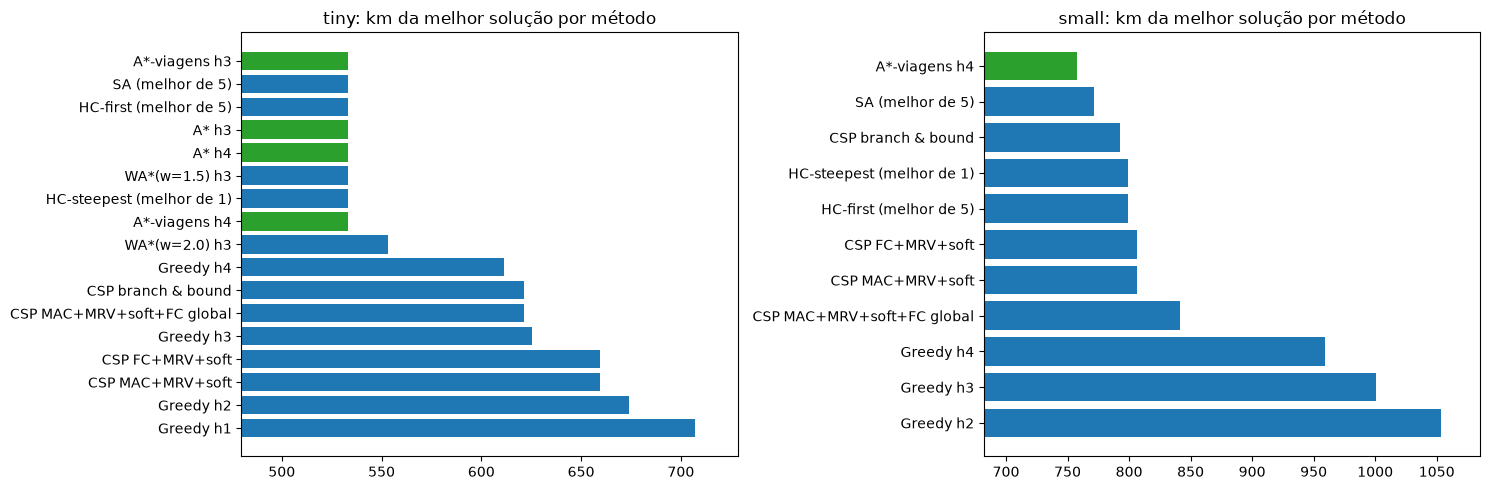

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, dataset in zip(axes, ("tiny", "small")):
    methods = comparison[(comparison.dataset == dataset) & comparison.km.notna()].sort_values("km")
    ax.barh(methods.metodo, methods.km,
            color=["tab:green" if method.startswith("A*") else "tab:blue" for method in methods.metodo])
    ax.set_xlim(methods.km.min() * 0.9, methods.km.max() * 1.03)
    ax.set_title(f"{dataset}: km da melhor solução por método")
    ax.invert_yaxis()
fig.tight_layout()

### 7.1 Melhor solução do small

{'tiny': {'km': 533.09, 'source': 'A*_h3_mst'}, 'small': {'km': 757.84, 'source': 'A*-viagens_h4_relaxed'}}
{'km': 757.84, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2515.7, 'route_min': 1466.7}
verificador: True
Veículo 1: W→P9→W | W→D15→D16→D6→D18→D19→D1→D9→D2→W | W→D23→D5→D25→D14→D11→D17→W
Veículo 2: W→P7→P11→P1→P3→P5→W | W→P8→P12→P2→P4→P6→P10→W | W→D7→D21→D24→D10→D22→D13→D8→D12→D3→D20→D4→W


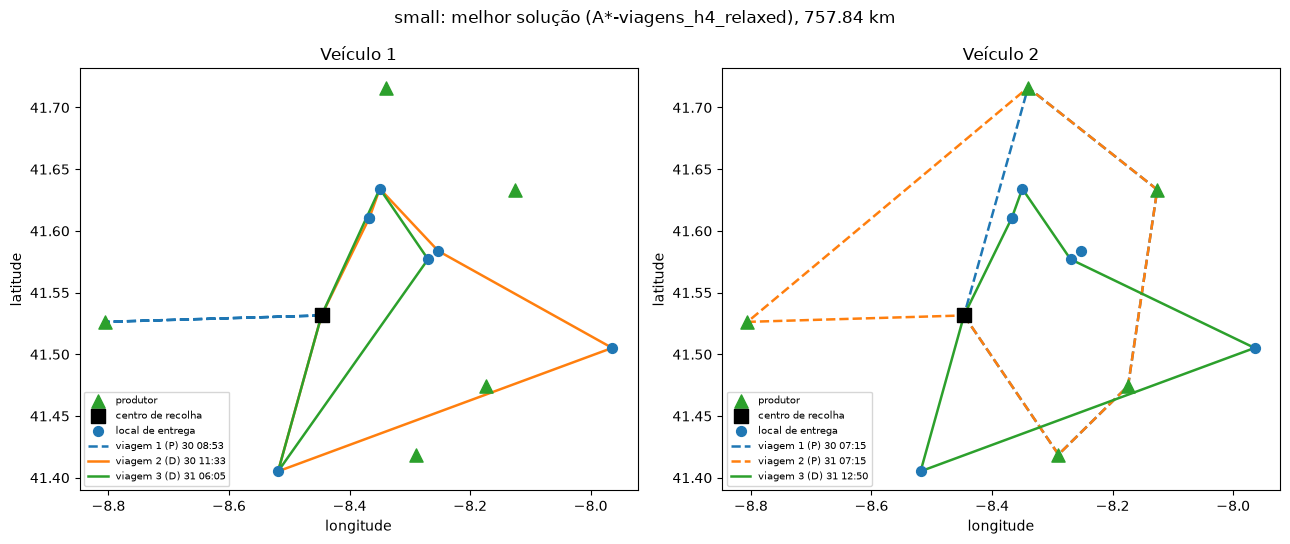

In [27]:
best = json.loads((REPORTS / "best.json").read_text())
print(best)
best_small = load_solution("solution_small_best.json")
small_eval = evaluate(small, best_small)
print(small_eval.summary())
print("verificador:", check_solution(small, small_eval).valid)
print_routes(best_small)
plot_routes(small, best_small, f"small: melhor solução ({best['small']['source']}), {small_eval.km:.2f} km");

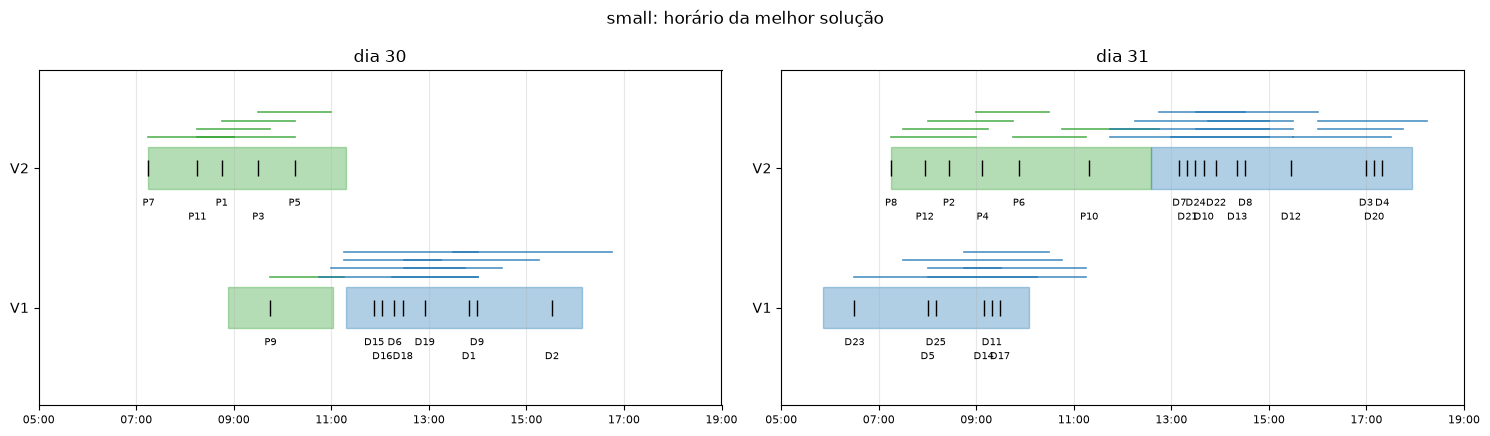

In [28]:
plot_gantt(small, small_eval, "small: horário da melhor solução");

### 7.2 Análise crítica

#### Qualidade das soluções

No tiny, o ótimo de 533,09 km foi provado pelo A\*. O HC e o A\* ponderado com w = 1,5 chegam lá em
décimas de segundo, e o SA em 1,2–1,4 s. O Greedy com h3 fica 17,3% acima, a primeira solução do
CSP (MAC + MRV + *soft*) 23,7% acima e o branch & bound 16,6% acima.

No small, o ótimo de 757,84 km foi provado pelo A\* por viagens com h4 em 19 expansões. A pesquisa local
fica entre 1,8% e 10,1% acima, a melhor primeira solução do CSP (FC ou MAC com MRV e *soft*, 806,18 km)
6,4% acima e o branch & bound (792,71 km) 4,6%. O A\* paragem a paragem não termina dentro do orçamento, nem com h4, o que mostra
que a escolha das ações pesa tanto como a heurística.

#### Tempos de execução

Medidos numa só execução num portátil; variam de máquina para máquina.

| Método | tiny | small |
|---|---|---|
| Greedy | milissegundos | até 0,95 s (h4) |
| A\* paragem a paragem | minutos (h3) | não termina |
| A\* por viagens (h4) | centésimas de segundo | cerca de 3 s, mais 18–36 s para o catálogo (feito uma vez) |
| Hill Climbing | centésimas a décimas de segundo | 0,4–1,0 s |
| SA (30 000 iterações) | 1,2–1,4 s | 2,0–2,5 s |
| CSP com FC ou MAC | centésimas de segundo | centésimas de segundo; 0,2–0,3 s com FC global |
| CSP com branch & bound | esgota o orçamento | esgota o orçamento |

O branch & bound demora 30 s no tiny e 45 s no small, o tempo de gastar o orçamento de atribuições.

#### Comparação entre famílias

A pesquisa informada dá garantias de otimalidade e completude. Escala mal quando a heurística é fraca
ou as ações são demasiado finas, mas com uma relaxação exata (h4) e ações ao nível da viagem provou o
ótimo dos dois datasets em segundos. O Greedy é a forma mais barata de ter uma primeira solução.

A pesquisa local não dá garantias. A partir de uma solução razoável chega a 0–10% do ótimo em menos de
3 s, e é a que melhor escalaria para instâncias maiores. Nestes dois datasets, no entanto, o A\* por
viagens com h4 faz melhor: prova o ótimo em 0,01 s no tiny e em cerca de 20–40 s no small, contando com
o catálogo.

O CSP é a forma mais natural de escrever as restrições, e a viabilidade está no centro deste problema. A
inferência (FC ou MAC) só compensa com restrições binárias que captem a estrutura temporal, como a de
sequência. O FC contra a restrição global quase elimina o backtracking (no máximo 3 no small), à custa de
mais verificações; o efeito nos km da primeira solução varia de dataset para dataset.

#### Limitações do modelo

Agrupar as recolhas pela interseção das janelas pode excluir soluções em que o mesmo produtor é visitado
duas vezes para linhas diferentes. As viagens homogéneas também custam: uma viagem mista, que
entregasse em Guimarães e recolhesse em Fafe no regresso, pouparia km, mas complicava a precedência. No
CSP, o modelo de posições fixa o número máximo de viagens por dia.

A partida *just in time* nunca atrasa recolhas para reduzir o tempo no armazém. Nestes dois datasets
isso não custa km: a h4 ignora tanto a partida *just in time* como o limite de 24 h e, mesmo
assim, no estado inicial já vale o ótimo. Se houver soluções mais curtas a ficar de fora, é por causa do
agrupamento das recolhas, das viagens homogéneas ou da regra da meia-noite.

#### Melhorias futuras

1. Viagens mistas (entregas e recolhas na mesma volta), com a precedência tratada linha a linha.
2. Recolhas parciais em vez da interseção das janelas, deixando a pesquisa decidir o agrupamento.
3. Levar o A\* por viagens a datasets maiores. O catálogo cresce com o número de pedidos por grupo;
   gerar as viagens por *column generation* e juntar à h4 o limite de 2 veículos ajudaria.
4. Uma vizinhança maior na pesquisa local (trocar viagens inteiras entre veículos, *or-opt*) e pesquisa
   local iterada.
5. Um CSP com os tempos como variáveis e propagação temporal (STN), ou CP-SAT para instâncias grandes.
6. Vários objetivos ao mesmo tempo (km, tempo de condução, equilíbrio entre veículos, emissões) e
   refrigeração, quando houver dados sobre os produtos.

## 8. Conclusão

O agente planeia recolhas e entregas que cumprem todas as regras do problema: janelas, capacidade,
passagem pelo armazém com permanência máxima, tempos de serviço e de manuseamento. Cada solução é
confirmada por um verificador independente que trabalha linha a linha sobre os CSV. Provámos o ótimo dos
dois datasets: 533,09 km no tiny e 757,84 km no small.

A pesquisa informada mostrou quanto pesam a heurística e a formulação. Da h1 à h4, o número de nós
expandidos cai várias ordens de grandeza, e passar de "uma paragem" para "uma viagem" por ação tornou o
small resolúvel de forma exata. A pesquisa local melhora depressa uma solução inicial (até 22,9% no
small) e é a que melhor escalaria, mas não garante o ótimo. O CSP, com pedidos atribuídos a viagens,
mostrou a diferença entre propagar restrições fracas e propagar restrições que captam a estrutura
temporal, como a sequência e o horário global.

Quanto ao processo, começámos pela análise exploratória, que decidiu boa parte da modelação: agrupar
recolhas, uma paragem por encomenda, viagens homogéneas. O código ficou dividido em módulos (`model`,
`informed`, `local_search`, `csp`), com testes unitários e um script que reproduz as experiências todas.
Usámos Python 3, pandas, matplotlib e Jupyter. A maior dificuldade foi a interação entre veículos através
do armazém, que obrigou a uma simulação guiada por dependências e a podas cuidadosas (dominância, ordens
de viagem) para o A\* continuar exato.